<a href="https://colab.research.google.com/github/Laxman26spy/EDA-House-Price-Analysis/blob/main/EDA_House_Prices_Mid_Term_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


In [ ]:
import pandas as pd
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:

# Import all  libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set visualization style
sns.set_style("whitegrid")

# Set default figure size
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

# Display dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:

# Count missing values in every column
missing = df.isnull().sum()

# Sort missing values in descending order
missing = missing.sort_values(ascending=False)

# Calculate missing percentage
missing_percentage = (missing / len(df)) * 100

# Create summary table
missing_data = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_percentage
})

# Display only columns with missing values
missing_data = missing_data[missing_data["Missing Values"] > 0]

display(missing_data)


,Missing Values,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageQual,81,5.547945
GarageFinish,81,5.547945
GarageType,81,5.547945


In [ ]:

# Identify numerical and categorical variables

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Total Numerical Variables:", len(numerical_cols))
print("Total Categorical Variables:", len(categorical_cols))
print("\nNumerical Variables:")
print(numerical_cols)
print("\nCategorical Variables:")
print(categorical_cols)


Total Numerical Variables: 38
Total Categorical Variables: 43

Numerical Variables:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Variables:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC',

In [ ]:

# Display variable classification

variable_summary = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.values
})

variable_summary["Variable Type"] = variable_summary["Data Type"].apply(
    lambda x: "Numerical" if np.issubdtype(x, np.number) else "Categorical"
)

display(variable_summary)


,Column Name,Data Type,Variable Type
0,Id,int64,Numerical
1,MSSubClass,int64,Numerical
2,MSZoning,object,Categorical
3,LotFrontage,float64,Numerical
4,LotArea,int64,Numerical
...,...,...,...
76,MoSold,int64,Numerical
77,YrSold,int64,Numerical
78,SaleType,object,Categorical
79,SaleCondition,object,Categorical


In [ ]:

# Ordinal categorical variables
ordinal_cols = [
    "ExterQual", "ExterCond",
    "BsmtQual", "BsmtCond",
    "HeatingQC", "KitchenQual",
    "FireplaceQu", "GarageQual",
    "GarageCond", "PoolQC",
    "Fence", "Functional",
    "LotShape", "Utilities",
    "LandSlope", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2",
    "GarageFinish", "PavedDrive"
]

# Nominal categorical variables
nominal_cols = [
    col for col in categorical_cols
    if col not in ordinal_cols
]

print("Ordinal Variables:", len(ordinal_cols))
print("Nominal Variables:", len(nominal_cols))
print("\nOrdinal Columns:")
print(ordinal_cols)
print("\nNominal Columns:")
print(nominal_cols)


Ordinal Variables: 20
Nominal Variables: 23

Ordinal Columns:
['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'Functional', 'LotShape', 'Utilities', 'LandSlope', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'GarageFinish', 'PavedDrive']

Nominal Columns:
['MSZoning', 'Street', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir', 'Electrical', 'GarageType', 'MiscFeature', 'SaleType', 'SaleCondition']


In [ ]:

# Convert ordinal columns into ordered categorical variables

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for column, order in ordinal_map.items():
    df[column] = pd.Categorical(
        df[column],
        categories=order,
        ordered=True
    )

print("Ordinal variables converted successfully!")



## Step 2: Observations

1. The dataset contains numerical and categorical variables.
2. Numerical variables represent measurable quantities.
3. Categorical variables represent labels or groups.
4. Ordinal variables have a meaningful order.
5. Nominal variables do not have a natural order.
6. Variable classification helps select suitable statistical
   techniques and visualizations.


In [ ]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:

# Calculate descriptive statistics for selected columns

columns = ["SalePrice", "GrLivArea", "LotArea"]

for column in columns:

    print("\n" + "=" * 50)
    print("Statistics for:", column)
    print("=" * 50)

    mean = df[column].mean()
    median = df[column].median()
    mode = df[column].mode().tolist()

    std = df[column].std()
    variance = df[column].var()

    data_range = df[column].max() - df[column].min()

    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    skewness = df[column].skew()
    kurtosis = df[column].kurt()

    print("Mean:", mean)
    print("Median:", median)
    print("Mode:", mode)
    print("Standard Deviation:", std)
    print("Variance:", variance)
    print("Range:", data_range)
    print("IQR:", iqr)
    print("Skewness:", skewness)
    print("Kurtosis:", kurtosis)


In [ ]:

# Compare mean and median

for column in columns:

    mean = df[column].mean()
    median = df[column].median()

    print("\nColumn:", column)
    print("Mean:", mean)
    print("Median:", median)

    if mean > median:
        print("Observation: Right Skewed")

    elif mean < median:
        print("Observation: Left Skewed")

    else:
        print("Observation: Approximately Symmetrical")


In [ ]:

# Analyse categorical variables

categorical_analysis = ["Neighborhood", "HouseStyle"]

for column in categorical_analysis:

    print("\n" + "=" * 40)
    print("Analysis of:", column)
    print("=" * 40)

    print("\nValue Counts:")
    print(df[column].value_counts())

    print("\nMode:")
    print(df[column].mode().tolist())



## Step 3: Descriptive Statistics — Observations

1. Descriptive statistics summarise numerical variables.
2. Mean and median measure central tendency.
3. Standard deviation and variance measure dispersion.
4. Range and IQR describe the spread of values.
5. Skewness measures distribution asymmetry.
6. Kurtosis describes the heaviness of distribution tails.
7. Value counts and mode summarise categorical variables.


In [ ]:

# Step 4: Distribution Analysis
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set plotting style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


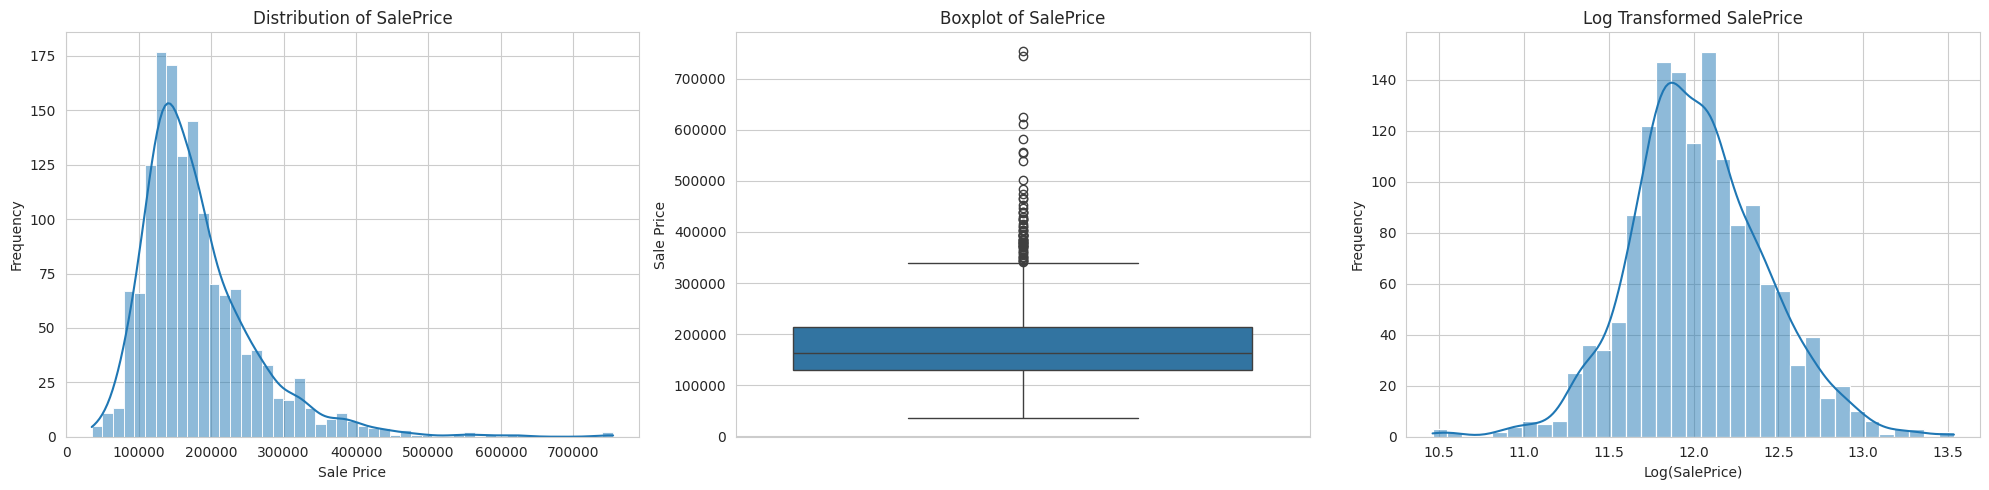

Original SalePrice Skewness: 1.8828757597682129
Log Transformed Skewness: 0.12134661989685333


In [ ]:

# Histogram, Boxplot and Log-transformed Histogram

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Histogram with KDE
sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("Sale Price")
axes[0].set_ylabel("Frequency")

# 2. Boxplot
sns.boxplot(y=df["SalePrice"], ax=axes[1])
axes[1].set_title("Boxplot of SalePrice")
axes[1].set_ylabel("Sale Price")

# 3. Log-transformed Histogram
log_saleprice = np.log1p(df["SalePrice"])

sns.histplot(log_saleprice, kde=True, ax=axes[2])
axes[2].set_title("Log Transformed SalePrice")
axes[2].set_xlabel("Log(SalePrice)")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Compare skewness
print("Original SalePrice Skewness:", df["SalePrice"].skew())
print("Log Transformed Skewness:", log_saleprice.skew())


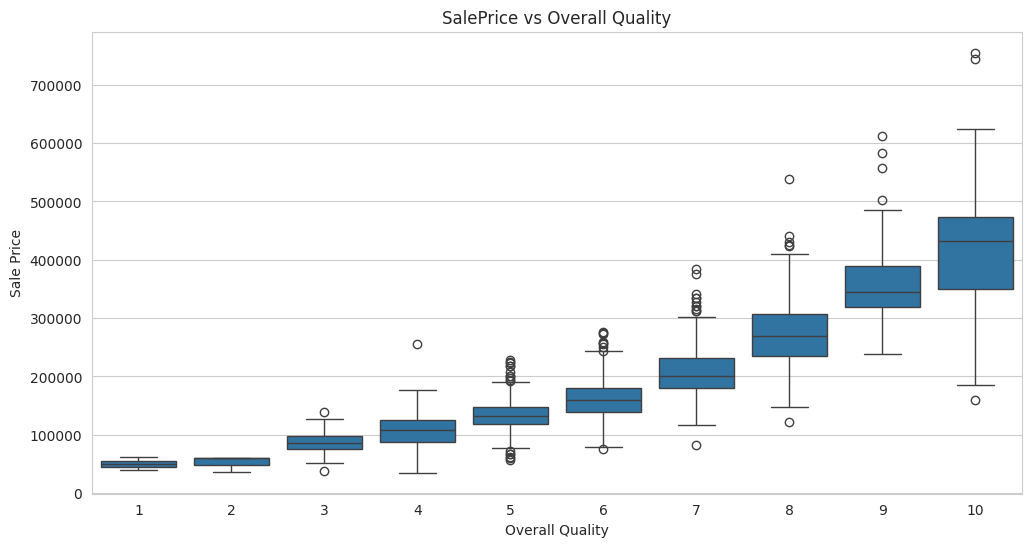

In [ ]:

# Boxplot of SalePrice grouped by OverallQual
plt.figure(figsize=(12, 6))

sns.boxplot(
    x="OverallQual",
    y="SalePrice",
    data=df
)

plt.title("SalePrice vs Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.show()


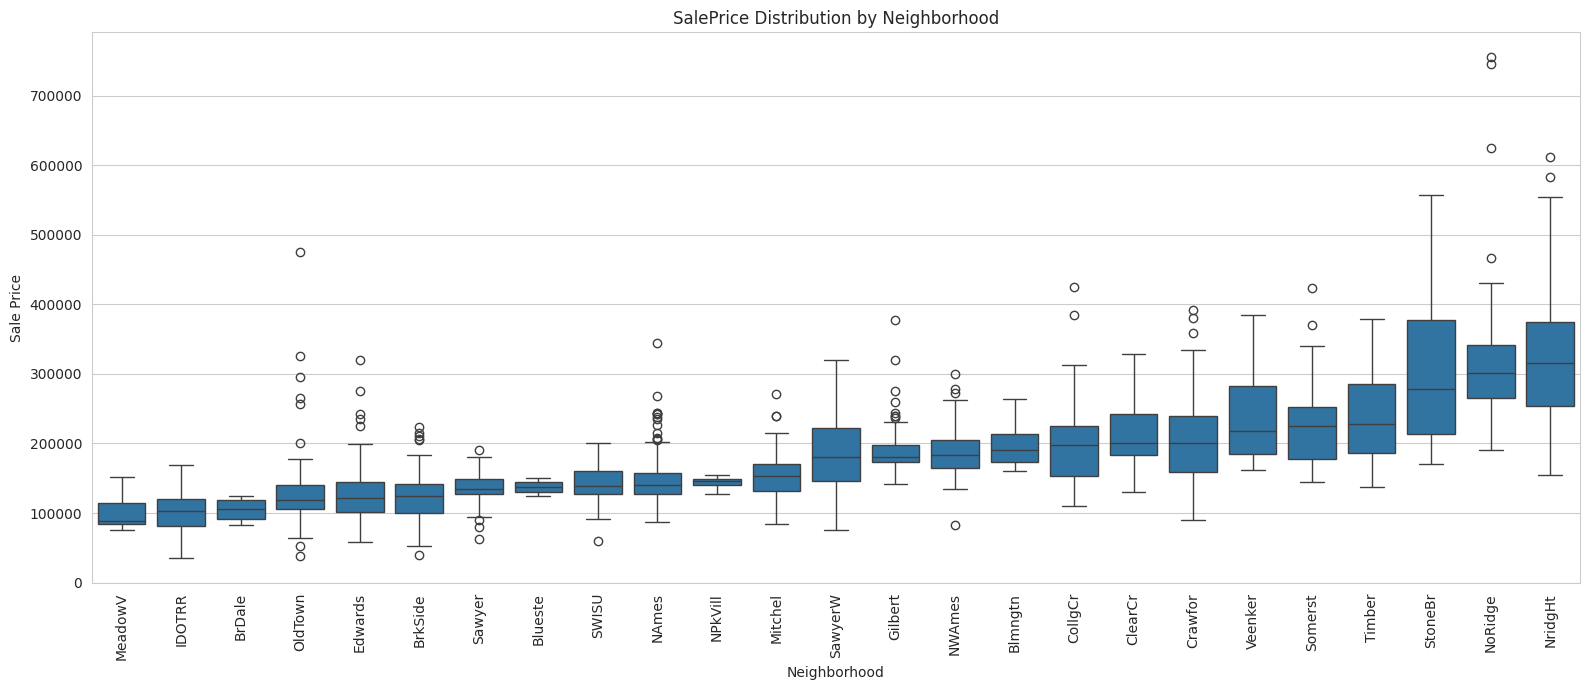

In [ ]:

# Boxplot of SalePrice grouped by Neighborhood

# Sort neighborhoods by median SalePrice
neighborhood_order = (
    df.groupby("Neighborhood", observed=True)["SalePrice"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(16, 7))

sns.boxplot(
    x="Neighborhood",
    y="SalePrice",
    data=df,
    order=neighborhood_order
)

plt.title("SalePrice Distribution by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()


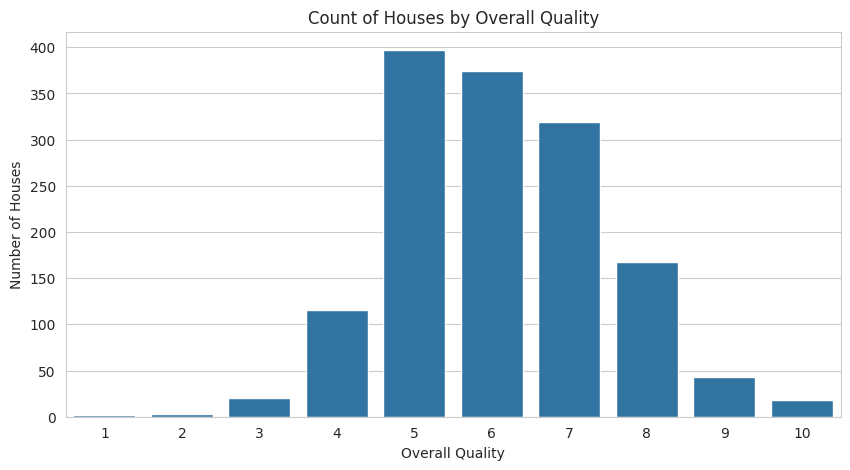

In [ ]:

# Countplot of OverallQual
plt.figure(figsize=(10, 5))

sns.countplot(
    x="OverallQual",
    data=df
)

plt.title("Count of Houses by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Number of Houses")

plt.show()


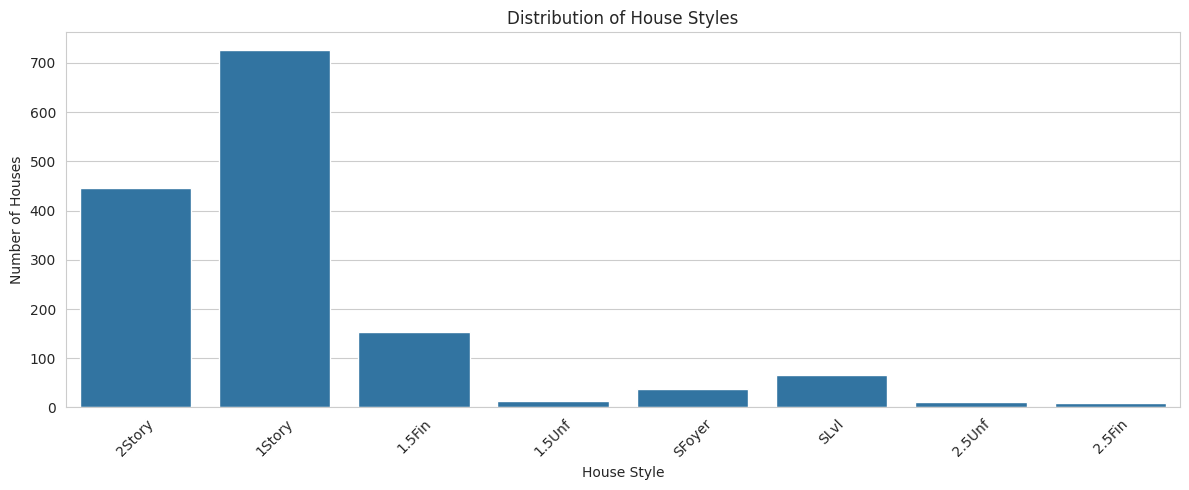

In [ ]:

# Countplot of HouseStyle
plt.figure(figsize=(12, 5))

sns.countplot(
    x="HouseStyle",
    data=df
)

plt.title("Distribution of House Styles")
plt.xlabel("House Style")
plt.ylabel("Number of Houses")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



## Step 4: Distributions — Observations

1. The SalePrice histogram shows the distribution of house prices.
2. The SalePrice boxplot helps identify the median, spread and potential outliers.
3. Log transformation helps reduce the right skewness of SalePrice.
4. Houses with higher OverallQual generally tend to have higher selling prices.
5. SalePrice varies across different neighborhoods.
6. The OverallQual countplot shows the frequency of houses at each quality level.
7. The HouseStyle countplot shows the distribution of different house styles.

### Conclusion
Distribution analysis helps understand the spread, skewness, frequency and outliers in the house price dataset.


In [ ]:

# Step 5: Correlation and Covariance

# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate covariance matrix
cov_matrix = numeric_df.cov()

# Calculate Pearson correlation matrix
corr_matrix = numeric_df.corr(method="pearson")
print("Covariance Matrix:")
display(cov_matrix)
print("Correlation Matrix:")
display(corr_matrix)


Covariance Matrix:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,177755.000000,198.968472,-108.390207,-1.398197e+05,-16.539068,5.915696,-1.618818e+02,-191.474297,-3.842688e+03,-9.661021e+02,...,-1.566468e+03,-1.332214e+01,74.450651,-576.428376,31.270391,966.275531,-1305.726525,24.133653,0.398561,-7.340732e+05
MSSubClass,198.968472,1789.338306,-404.439075,-5.901742e+04,1.908771,-2.792117,3.558134e+01,35.439934,1.758378e+02,-1.347356e+03,...,-6.669453e+01,-1.709661e+01,-31.119180,-54.348569,-61.394007,14.076652,-161.243759,-1.553607,-1.202630,-2.832337e+05
LotFrontage,-108.390207,-404.439075,589.749169,8.199814e+04,8.673047,-1.573935,9.510848e+01,45.744675,8.712074e+02,2.635953e+03,...,2.587889e+02,2.438681e+02,16.022614,48.936214,56.264418,194.586364,15.520479,0.735389,0.240700,7.124262e+05
LotArea,-139819.667238,-59017.418634,81998.138404,9.962565e+07,1460.548271,-62.602871,4.289113e+03,2841.343594,1.884014e+05,9.746908e+05,...,2.148006e+05,5.606253e+04,-11188.088772,5976.210971,24020.024881,31148.209380,188508.749657,32.517342,-189.050203,2.092111e+08
OverallQual,-16.539068,1.908771,8.673047,1.460548e+03,1.912679,-0.141484,2.390622e+01,15.723417,1.030121e+02,1.511770e+02,...,4.141573e+01,2.829764e+01,-9.630806,1.231398,5.003537,3.620945,-21.548945,0.264785,-0.050229,8.690413e+04
OverallCond,5.915696,-2.792117,-1.573935,-6.260287e+01,-0.141484,1.238322,-1.263671e+01,1.694152,-2.581896e+01,-2.346427e+01,...,-4.649741e-01,-2.402762e+00,4.785160,0.832039,3.400819,-0.088745,37.970669,-0.010563,0.064953,-6.882739e+03
YearBuilt,-161.881768,35.581337,95.108483,4.289113e+03,23.906215,-12.636709,9.122154e+02,369.675456,1.725993e+03,3.437028e+03,...,8.513053e+02,3.775838e+02,-714.886948,27.763434,-84.815514,6.006353,-515.209195,1.012426,-0.546237,1.254637e+06
YearRemodAdd,-191.474297,35.439934,45.744675,2.841344e+03,15.723417,1.694152,3.696755e+02,426.232822,6.716764e+02,1.209533e+03,...,5.323509e+02,3.095486e+02,-244.692937,27.410061,-44.594964,4.835329,-105.358566,1.199517,0.980046,8.317079e+05
MasVnrArea,-3842.687941,175.837842,871.207424,1.884014e+05,103.012054,-25.818956,1.725993e+03,671.676358,3.278497e+04,2.182760e+04,...,3.626330e+03,1.503301e+03,-1218.999064,100.044636,622.125969,85.516034,-2685.666442,-2.915638,-1.973363,6.854858e+06
BsmtFinSF1,-966.102125,-1347.355751,2635.952669,9.746908e+05,151.176998,-23.464270,3.437028e+03,1209.532821,2.182760e+04,2.080255e+05,...,1.167953e+04,3.377322e+03,-2851.840396,353.685020,1577.237193,2574.473738,808.155748,-19.393195,8.697797,1.400137e+07


Correlation Matrix:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


In [ ]:

# Find top 10 features correlated with SalePrice

top_corr = corr_matrix["SalePrice"].drop(
    labels=["SalePrice", "Id"],
    errors="ignore"
).abs().sort_values(ascending=False)

top10_features = top_corr.head(10)

print("Top 10 Features Correlated with SalePrice:")
display(top10_features)


Top 10 Features Correlated with SalePrice:


,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


In [ ]:

# Step 5.3: Compare Covariance and Correlation for Top 3 Features

# Recalculate numerical data
numeric_df = df.select_dtypes(include=np.number)

# Recalculate covariance and correlation
cov_matrix = numeric_df.cov()
corr_matrix = numeric_df.corr(method="pearson")

# Find top correlated features
top_corr = corr_matrix["SalePrice"].drop(
    labels=["SalePrice", "Id"],
    errors="ignore"
).abs().sort_values(ascending=False)

# Select top 3 features
top3_features = top_corr.head(3).index

# Display comparison
for feature in top3_features:

    print("\nFeature:", feature)

    print("Covariance with SalePrice:",
          cov_matrix.loc[feature, "SalePrice"])

    print("Correlation with SalePrice:",
          corr_matrix.loc[feature, "SalePrice"])



Feature: OverallQual
Covariance with SalePrice: 86904.12583679946
Correlation with SalePrice: 0.7909816005838053

Feature: GrLivArea
Covariance with SalePrice: 29581866.743236575
Correlation with SalePrice: 0.7086244776126515

Feature: GarageCars
Covariance with SalePrice: 38020.18135897172
Correlation with SalePrice: 0.6404091972583519


In [ ]:

# Step 5.4: Spearman Correlation for Ordinal Columns

# Create a separate DataFrame
spearman_df = df[["OverallQual", "ExterQual",
                  "KitchenQual", "SalePrice"]].copy()

# Define the correct quality order
quality_order = ["Po", "Fa", "TA", "Gd", "Ex"]

# Convert categorical quality values into ordered numbers
for col in ["ExterQual", "KitchenQual"]:
    spearman_df[col] = pd.Categorical(
        spearman_df[col],
        categories=quality_order,
        ordered=True
    ).codes

    # Replace missing values (-1) with NaN
    spearman_df[col] = spearman_df[col].replace(-1, np.nan)

# Calculate Spearman correlation
spearman_corr = spearman_df.corr(method="spearman")

print("Spearman Correlation Matrix:")
display(spearman_corr)


Spearman Correlation Matrix:


,OverallQual,ExterQual,KitchenQual,SalePrice
OverallQual,1.000000,0.715988,0.660498,0.809829
ExterQual,0.715988,1.000000,0.725266,0.684014
KitchenQual,0.660498,0.725266,1.000000,0.672849
SalePrice,0.809829,0.684014,0.672849,1.000000



## Step 5: Correlation and Covariance — Observations

1. Covariance measures how two numerical variables change together.
2. Pearson correlation measures the strength and direction of a linear relationship.
3. Correlation values range from -1 to +1.
4. Features with higher absolute correlation have stronger linear relationships with SalePrice.
5. Correlation is easier to compare than covariance because it is standardised.
6. Spearman correlation is useful for analysing ordinal variables.

### Correlation vs Causation

Correlation does not mean causation.

For example, GarageArea and GarageCars may be positively correlated because houses with more garage space can accommodate more cars.

This does not mean that increasing garage area directly causes an increase in house prices.


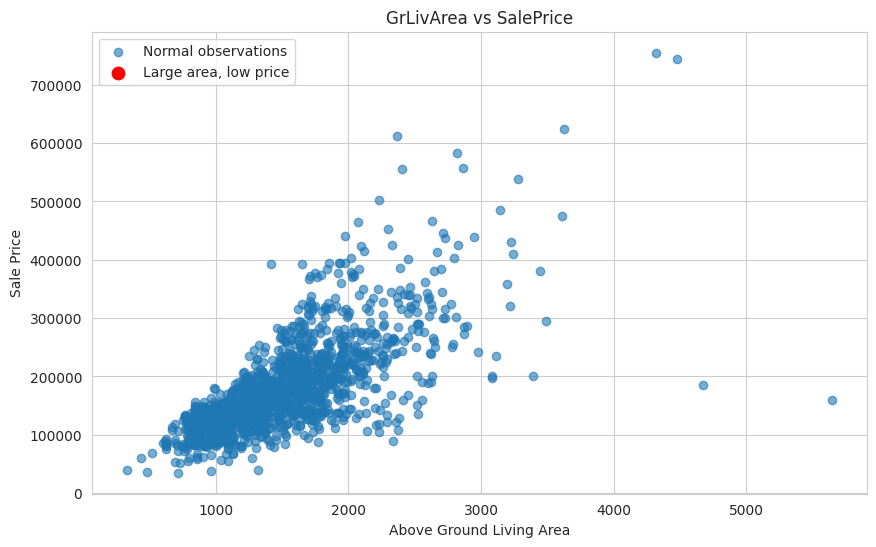

Number of unusual points: 0


In [ ]:

# Step 6.1: Scatter Plot - GrLivArea vs SalePrice

plt.figure(figsize=(10, 6))

# Identify large houses with unusually low selling prices
low_price_limit = df["SalePrice"].quantile(0.25)

unusual_points = (
    (df["GrLivArea"] > 4000) &
    (df["SalePrice"] < low_price_limit)
)

# Plot all houses
plt.scatter(
    df["GrLivArea"],
    df["SalePrice"],
    alpha=0.6,
    label="Normal observations"
)

# Highlight unusual observations
plt.scatter(
    df.loc[unusual_points, "GrLivArea"],
    df.loc[unusual_points, "SalePrice"],
    color="red",
    s=80,
    label="Large area, low price"
)

plt.title("GrLivArea vs SalePrice")
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")
plt.legend()
plt.show()

print("Number of unusual points:", unusual_points.sum())


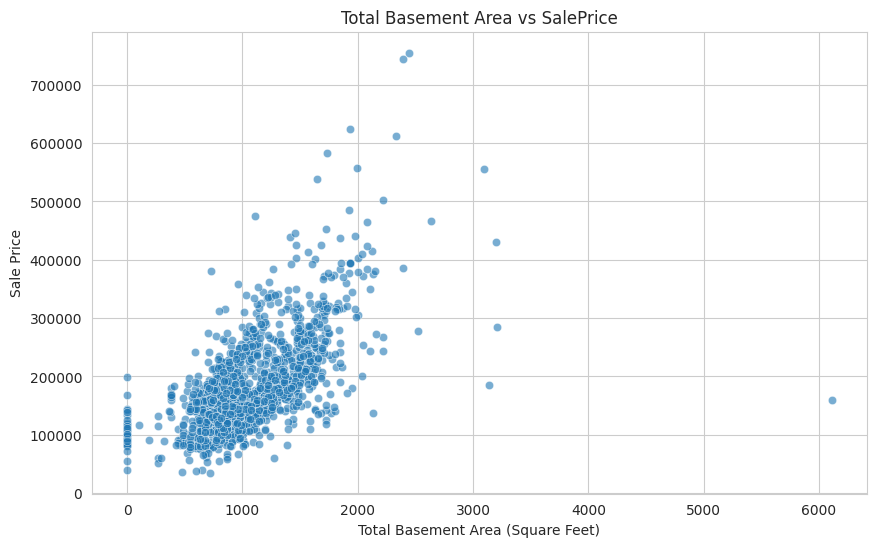

In [ ]:

# Step 6.2: Scatter Plot - TotalBsmtSF vs SalePrice

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="TotalBsmtSF",
    y="SalePrice",
    alpha=0.6
)

plt.title("Total Basement Area vs SalePrice")
plt.xlabel("Total Basement Area (Square Feet)")
plt.ylabel("Sale Price")

plt.show()


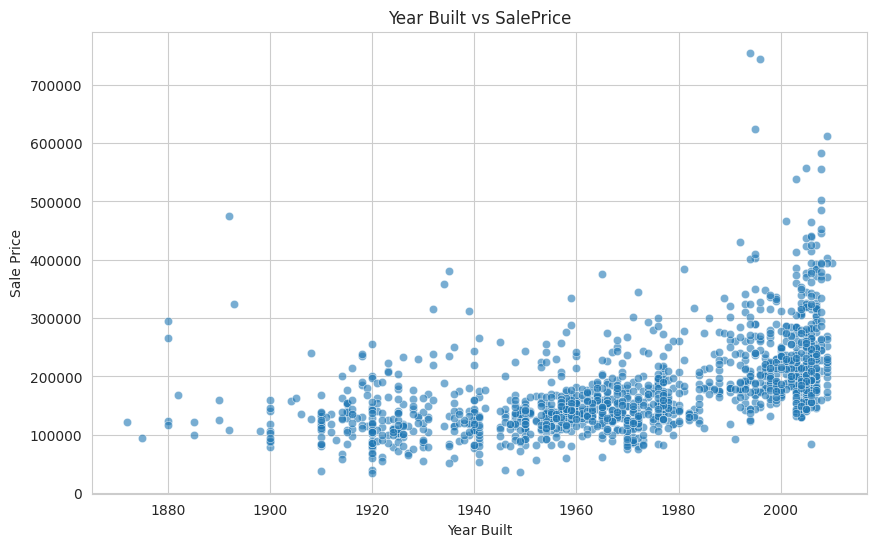

In [ ]:

# Step 6.3: Scatter Plot - YearBuilt vs SalePrice

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="YearBuilt",
    y="SalePrice",
    alpha=0.6
)

plt.title("Year Built vs SalePrice")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")

plt.show()


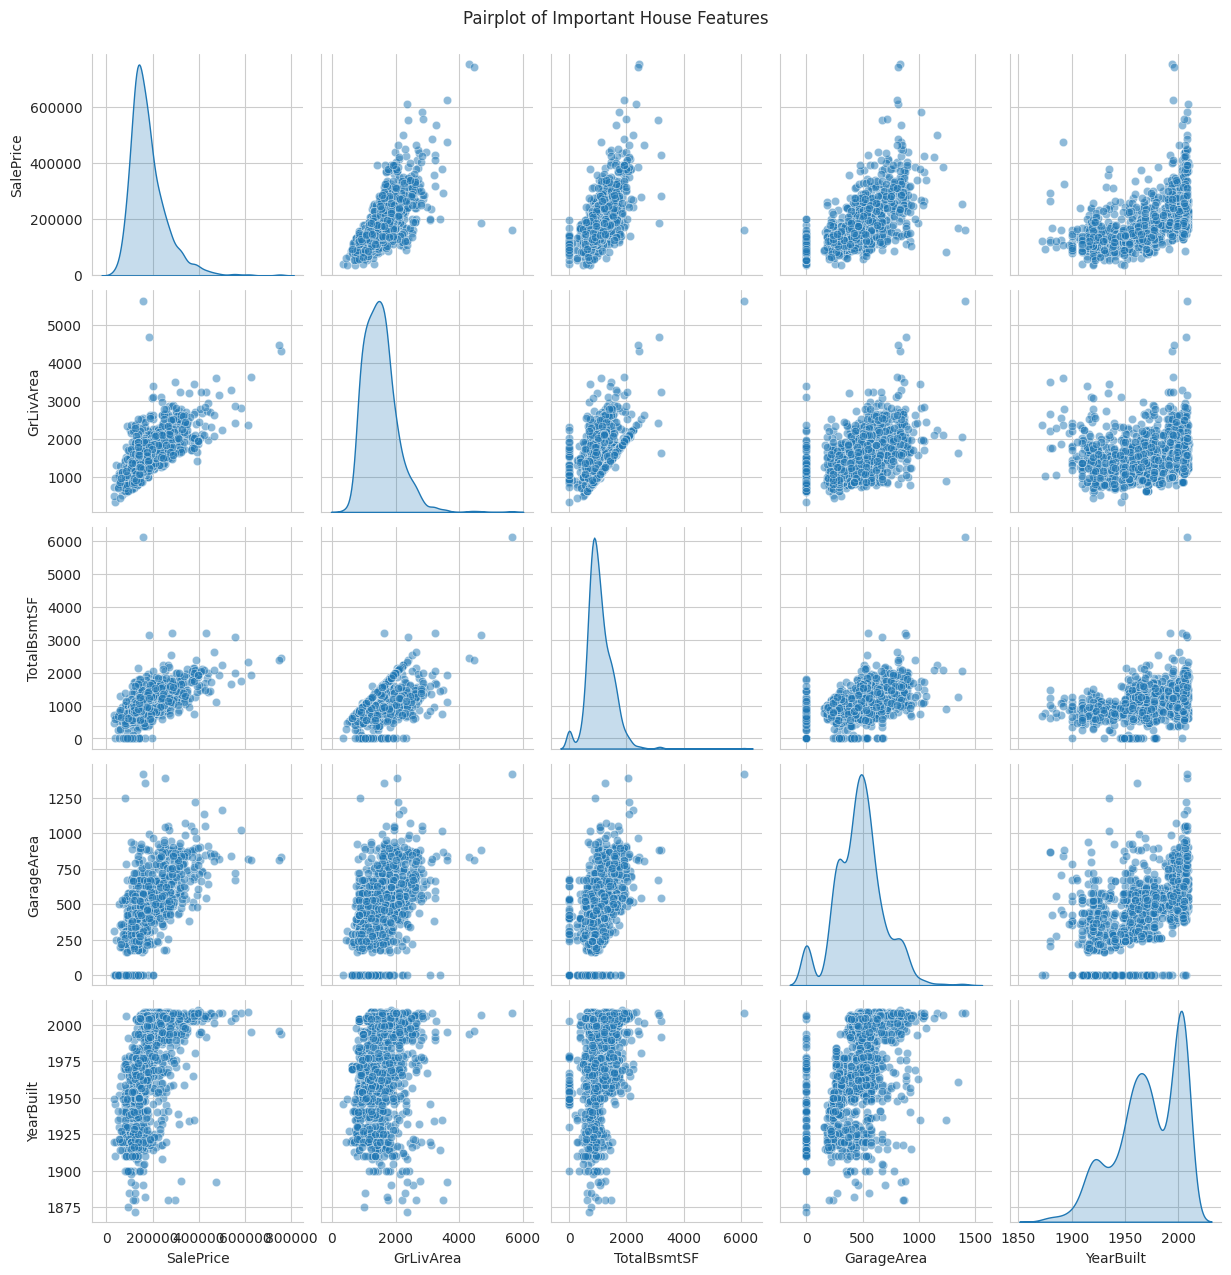

In [ ]:

# Step 6.4: Pairplot of Selected Features

selected = [
    "SalePrice",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt"
]

sns.pairplot(
    df[selected],
    diag_kind="kde",
    plot_kws={"alpha": 0.5}
)

plt.suptitle(
    "Pairplot of Important House Features",
    y=1.02
)

plt.show()



## Step 6: Scatter Plots and Pair Plots — Observations

1. GrLivArea and SalePrice generally show a positive relationship.
2. Some large houses have relatively low selling prices and may represent unusual observations.
3. TotalBsmtSF generally shows a positive relationship with SalePrice.
4. YearBuilt helps us understand the relationship between construction year and selling price.
5. Pairplots help visualise relationships among multiple numerical features.
6. KDE plots on the diagonal show the distribution of individual features.

### Conclusion
Scatter plots and pairplots help identify relationships, trends and unusual observations in the housing dataset.


In [ ]:

# Step 7.1: Select Top 10 Features

# Calculate correlation among numerical columns
numeric_df = df.select_dtypes(include=np.number)

corr_matrix = numeric_df.corr()

# Select 10 features most correlated with SalePrice
top10 = (
    corr_matrix["SalePrice"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index
)

print("Top 10 Features:")
print(list(top10))


Top 10 Features:
['SalePrice', 'OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt']


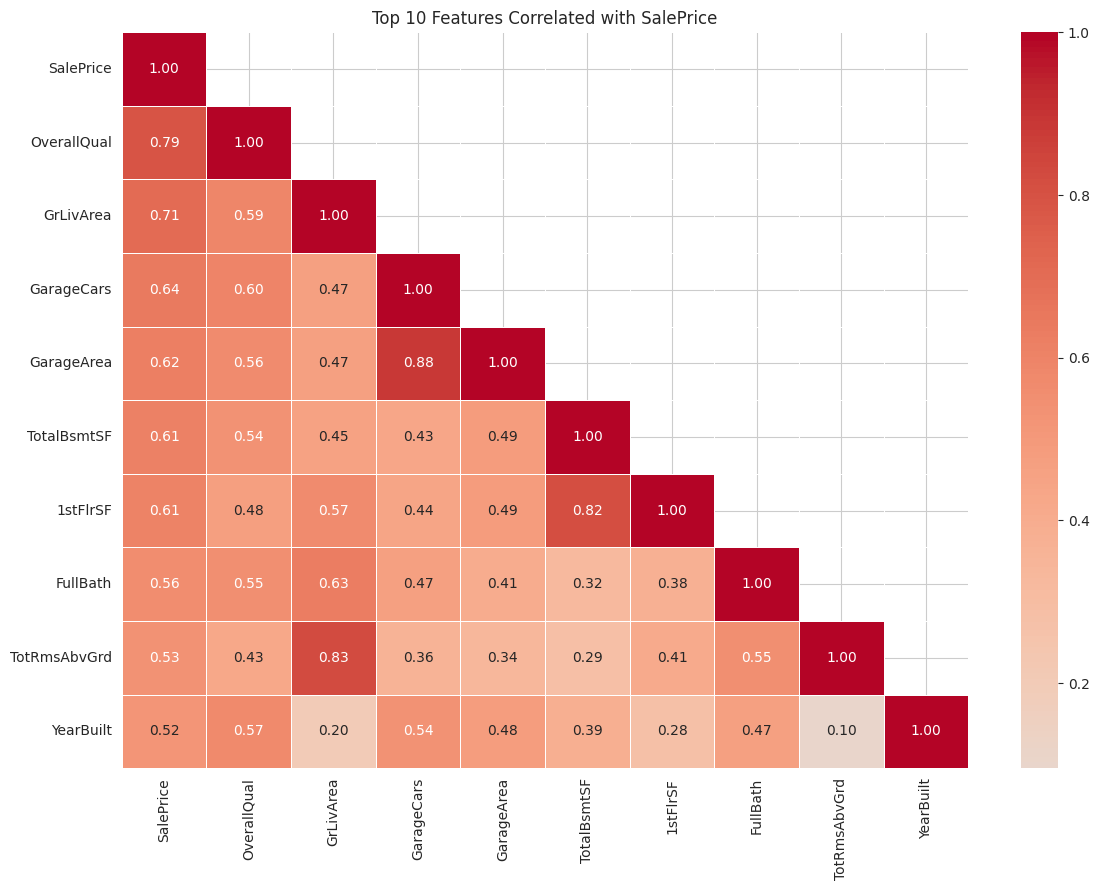

In [ ]:

# Step 7.2: Correlation Heatmap

corr_top = numeric_df[top10].corr()

# Create mask for upper triangle
mask = np.triu(np.ones_like(corr_top, dtype=bool), k=1)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_top,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    mask=mask,
    linewidths=0.5
)

plt.title("Top 10 Features Correlated with SalePrice")
plt.tight_layout()
plt.show()



## Step 7: Correlation Heatmap — Observations

1. The heatmap displays correlations among the top 10 numerical features.
2. Positive correlation indicates that two variables tend to increase together.
3. Negative correlation indicates an inverse relationship.
4. Values closer to +1 indicate strong positive correlation.
5. Values closer to -1 indicate strong negative correlation.
6. Values closer to 0 indicate weak linear correlation.

### Conclusion
The correlation heatmap provides a clear visual representation of relationships between important numerical features and helps identify strongly correlated variables.


In [ ]:

# Step 8.1: Outlier Detection

# IQR Method
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return series[(series < lower) | (series > upper)]


# Z-Score Method
def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return series[abs(z) > threshold]


# Compare outliers
for column in ["GrLivArea", "SalePrice"]:

    a = iqr_outliers(df[column])
    b = zscore_outliers(df[column])

    print("\nColumn:", column)
    print("IQR Outliers:", len(a))
    print("Z-Score Outliers:", len(b))
    print("Overlap:", len(set(a.index) & set(b.index)))



Column: GrLivArea
IQR Outliers: 31
Z-Score Outliers: 16
Overlap: 16

Column: SalePrice
IQR Outliers: 61
Z-Score Outliers: 22
Overlap: 22


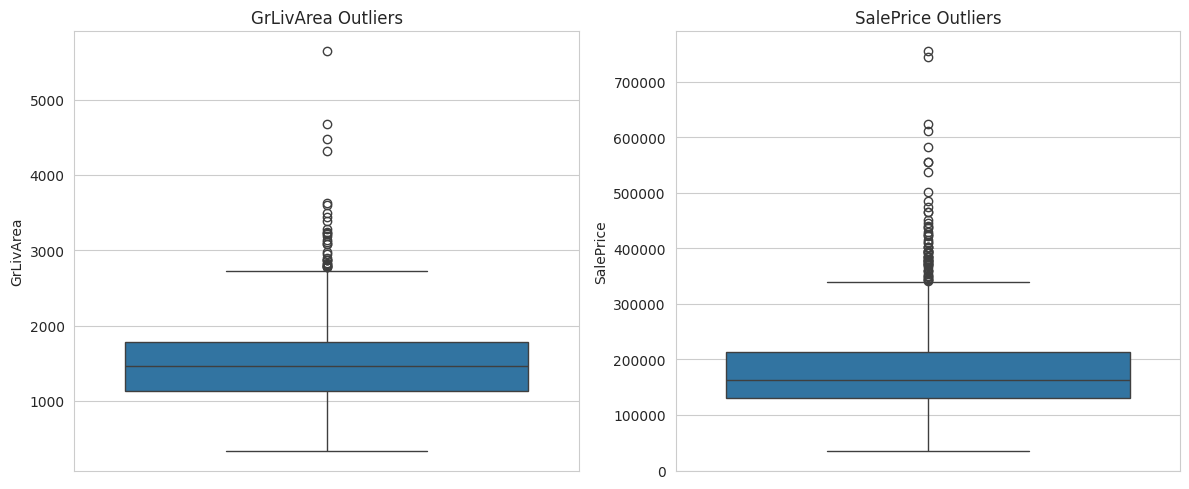

In [ ]:

# Step 8.2: Boxplots

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["GrLivArea"], ax=axes[0])
axes[0].set_title("GrLivArea Outliers")

sns.boxplot(y=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Outliers")

plt.tight_layout()
plt.show()


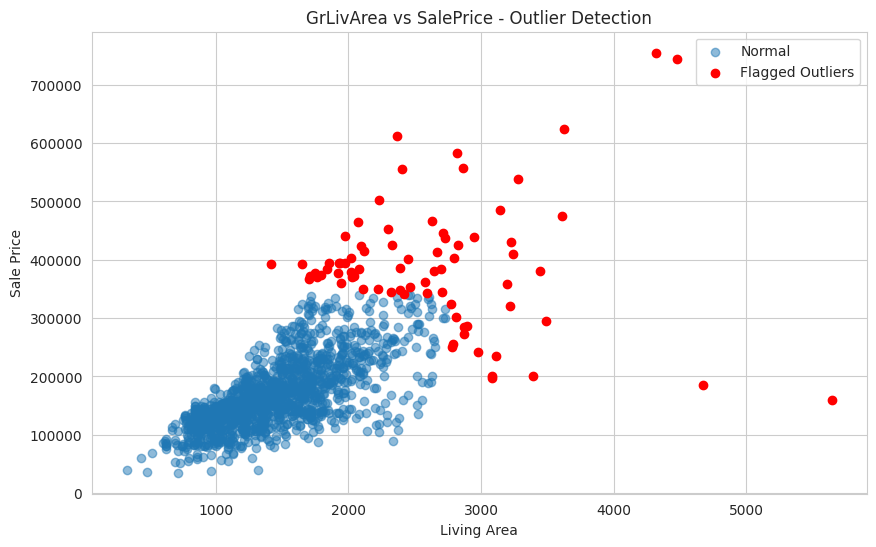

In [ ]:

# Step 8.3: Highlight Outliers

area_outliers = iqr_outliers(df["GrLivArea"])
price_outliers = iqr_outliers(df["SalePrice"])

flagged_indices = set(area_outliers.index) | set(price_outliers.index)

normal = df.loc[~df.index.isin(flagged_indices)]
outliers = df.loc[df.index.isin(flagged_indices)]

plt.figure(figsize=(10, 6))

plt.scatter(normal["GrLivArea"], normal["SalePrice"],
            alpha=0.5, label="Normal")

plt.scatter(outliers["GrLivArea"], outliers["SalePrice"],
            color="red", label="Flagged Outliers")

plt.title("GrLivArea vs SalePrice - Outlier Detection")
plt.xlabel("Living Area")
plt.ylabel("Sale Price")
plt.legend()
plt.show()



## Step 8: Outlier Detection — Observations

1. IQR and Z-score methods identify unusual observations.
2. IQR detects outliers using quartiles and interquartile range.
3. Z-score detects values more than 3 standard deviations from the mean.
4. Some observations are detected by both methods.
5. Large houses with unusually low prices may be unusual sales.

### Conclusion
Outlier detection helps identify unusual observations that may affect data analysis. Outliers should be investigated before deciding whether to remove or retain them.


In [ ]:

# Step 9.1: Check Duplicate Rows

dup_count = df.duplicated().sum()

print("Duplicate Rows:", dup_count)

if dup_count > 0:
    df = df.drop_duplicates()
    print("Duplicates Removed!")
    print("New Dataset Shape:", df.shape)
else:
    print("No Duplicate Rows Found!")


Duplicate Rows: 0
No Duplicate Rows Found!


In [ ]:

# Step 9.2: Check Categorical Inconsistencies

for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].unique())




# Standardize categorical values

for col in categorical_cols:
    df[col] = df[col].apply(
        lambda x: x.strip().lower() if isinstance(x, str) else x
    )

print("Categorical values standardized!")



Column: MSZoning
['rl' 'rm' 'c (all)' 'fv' 'rh']

Column: Street
['pave' 'grvl']

Column: Alley
[nan 'grvl' 'pave']

Column: LotShape
['reg' 'ir1' 'ir2' 'ir3']

Column: LandContour
['lvl' 'bnk' 'low' 'hls']

Column: Utilities
['allpub' 'nosewa']

Column: LotConfig
['inside' 'fr2' 'corner' 'culdsac' 'fr3']

Column: LandSlope
['gtl' 'mod' 'sev']

Column: Neighborhood
['collgcr' 'veenker' 'crawfor' 'noridge' 'mitchel' 'somerst' 'nwames'
 'oldtown' 'brkside' 'sawyer' 'nridght' 'names' 'sawyerw' 'idotrr'
 'meadowv' 'edwards' 'timber' 'gilbert' 'stonebr' 'clearcr' 'npkvill'
 'blmngtn' 'brdale' 'swisu' 'blueste']

Column: Condition1
['norm' 'feedr' 'posn' 'artery' 'rrae' 'rrnn' 'rran' 'posa' 'rrne']

Column: Condition2
['norm' 'artery' 'rrnn' 'feedr' 'posn' 'posa' 'rran' 'rrae']

Column: BldgType
['1fam' '2fmcon' 'duplex' 'twnhse' 'twnhs']

Column: HouseStyle
['2story' '1story' '1.5fin' '1.5unf' 'sfoyer' 'slvl' '2.5unf' '2.5fin']

Column: RoofStyle
['gable' 'hip' 'gambrel' 'mansard' 'flat' '

In [ ]:

# Step 9.3: Handle Missing Categorical Values

missing_cols = [
    "PoolQC", "Alley", "Fence",
    "FireplaceQu", "GarageType"
]

for col in missing_cols:
    df[col] = df[col].fillna("None")

print("Categorical missing values handled!")


Categorical missing values handled!


In [ ]:

# Step 9.4: Handle Numerical Missing Values

df["LotFrontage"] = df.groupby("Neighborhood")[
    "LotFrontage"
].transform(lambda x: x.fillna(x.median()))

df["LotFrontage"] = df["LotFrontage"].fillna(
    df["LotFrontage"].median()
)

print("LotFrontage missing values handled!")


LotFrontage missing values handled!


In [ ]:

# Step 9.5: Check Remaining Missing Values

print("Total Missing Values:", df.isnull().sum().sum())

missing_summary = df.isnull().sum()
display(missing_summary[missing_summary > 0])


Total Missing Values: 2798


,0
MasVnrType,872
MasVnrArea,8
BsmtQual,37
BsmtCond,37
BsmtExposure,38
BsmtFinType1,37
BsmtFinType2,38
Electrical,1
GarageYrBlt,81
GarageFinish,81


In [ ]:

# Step 9.6: Check Impossible Values

print("YearBuilt > YrSold:")
display(df[df["YearBuilt"] > df["YrSold"]])

print("Negative Area Values:")

area_cols = [
    "LotArea", "GrLivArea",
    "TotalBsmtSF", "GarageArea"
]

for col in area_cols:
    print(col, ":", (df[col] < 0).sum())


YearBuilt > YrSold:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


Negative Area Values:
LotArea : 0
GrLivArea : 0
TotalBsmtSF : 0
GarageArea : 0



## Step 9: Data Quality Checks — Observations

1. Checked and handled duplicate records.
2. Standardized categorical values.
3. Replaced missing values in selected categorical columns with "None".
4. Handled missing LotFrontage values using Neighborhood median.
5. Verified remaining missing values.
6. Checked impossible year and negative area values.

### Conclusion
Data quality checks improve dataset reliability and consistency before further analysis.


In [ ]:

# Step 10.1: Project Summary

print("=" * 50)
print("       HOUSE PRICE EDA - PROJECT SUMMARY")
print("=" * 50)

print("\nDataset Information:")
print("Total Houses:", df.shape[0])
print("Total Features:", df.shape[1])

print("\nSale Price Statistics:")
print("Average Sale Price:", df["SalePrice"].mean())
print("Median Sale Price:", df["SalePrice"].median())
print("Minimum Sale Price:", df["SalePrice"].min())
print("Maximum Sale Price:", df["SalePrice"].max())

print("\nMissing Values:", df.isnull().sum().sum())

print("\nProject Summary Generated Successfully!")


       HOUSE PRICE EDA - PROJECT SUMMARY

Dataset Information:
Total Houses: 1460
Total Features: 81

Sale Price Statistics:
Average Sale Price: 180921.19589041095
Median Sale Price: 163000.0
Minimum Sale Price: 34900
Maximum Sale Price: 755000

Missing Values: 2798

Project Summary Generated Successfully!


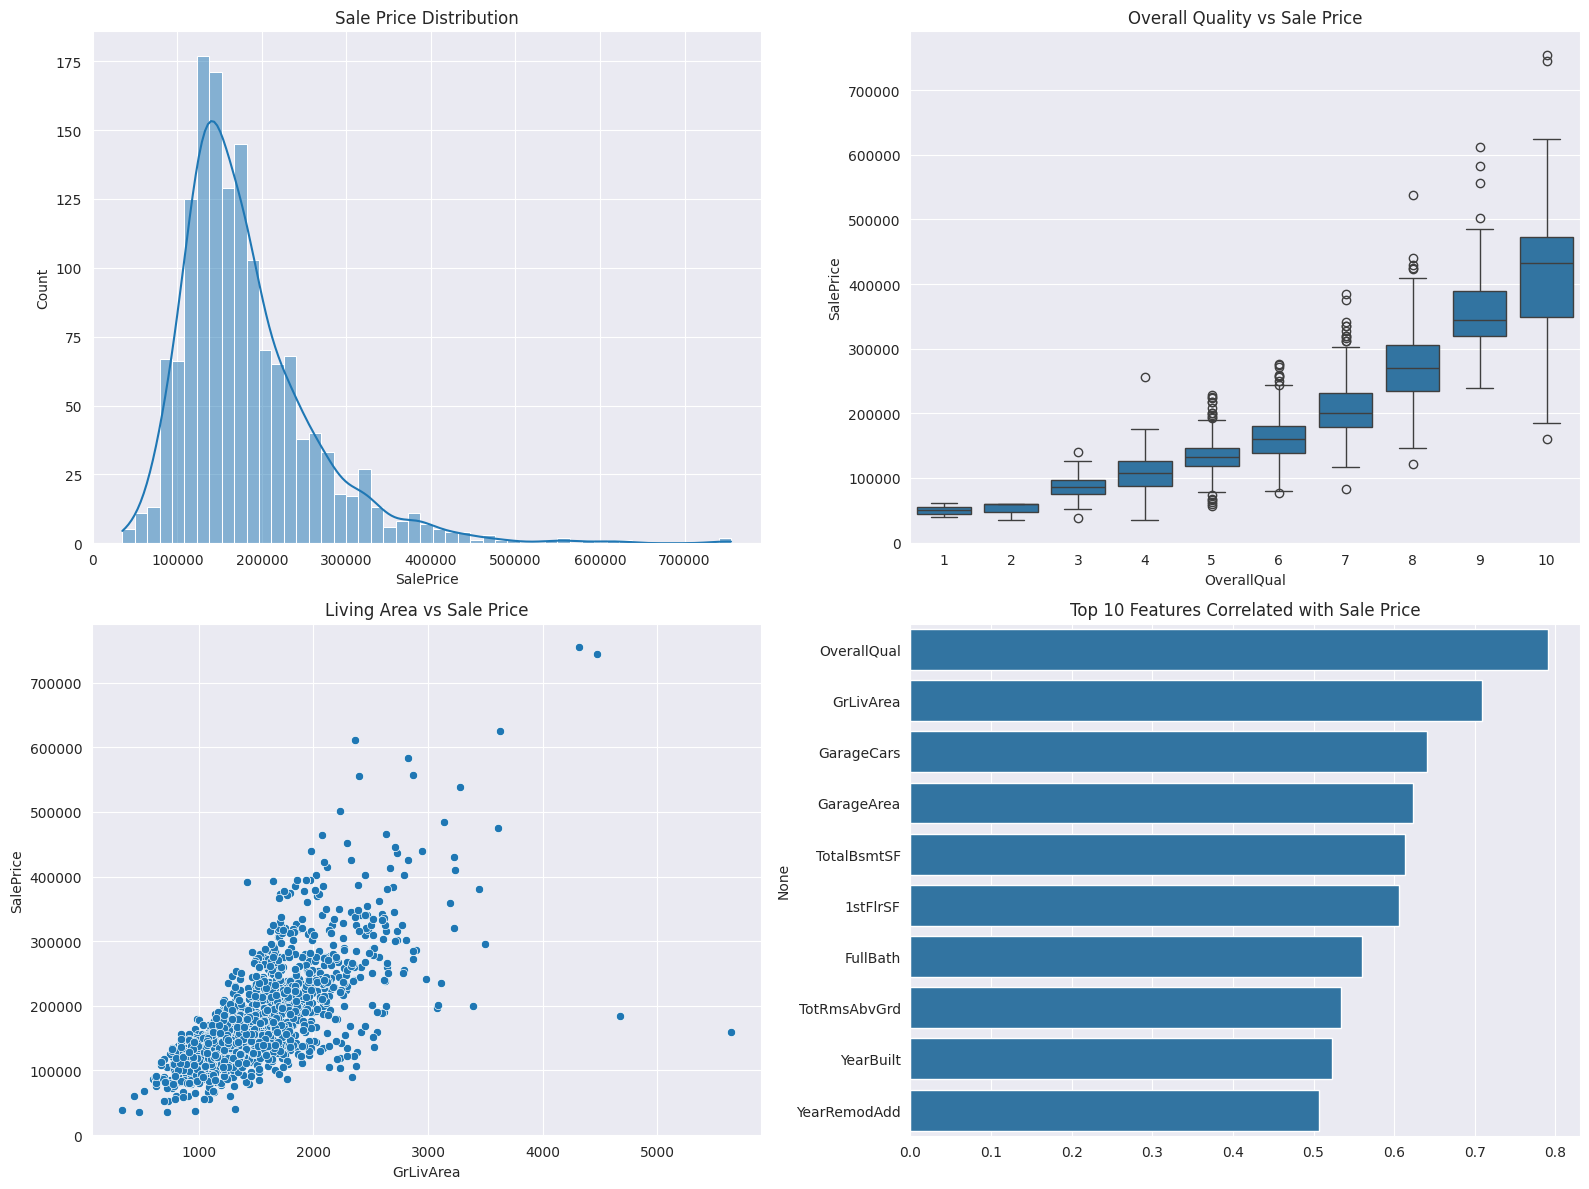

In [ ]:

# Step 10.2: Data Visualization Dashboard

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Sale Price Distribution
sns.histplot(df["SalePrice"], kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Sale Price Distribution")

# 2. Overall Quality vs Sale Price
sns.boxplot(x="OverallQual", y="SalePrice", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Overall Quality vs Sale Price")

# 3. Living Area vs Sale Price
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Living Area vs Sale Price")

# 4. Top Correlated Features
corr = df.select_dtypes(include="number").corr()["SalePrice"]
top_features = corr.drop("SalePrice").abs().nlargest(10).index

sns.barplot(
    x=corr[top_features].values,
    y=top_features,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Top 10 Features Correlated with Sale Price")

plt.tight_layout()
plt.show()


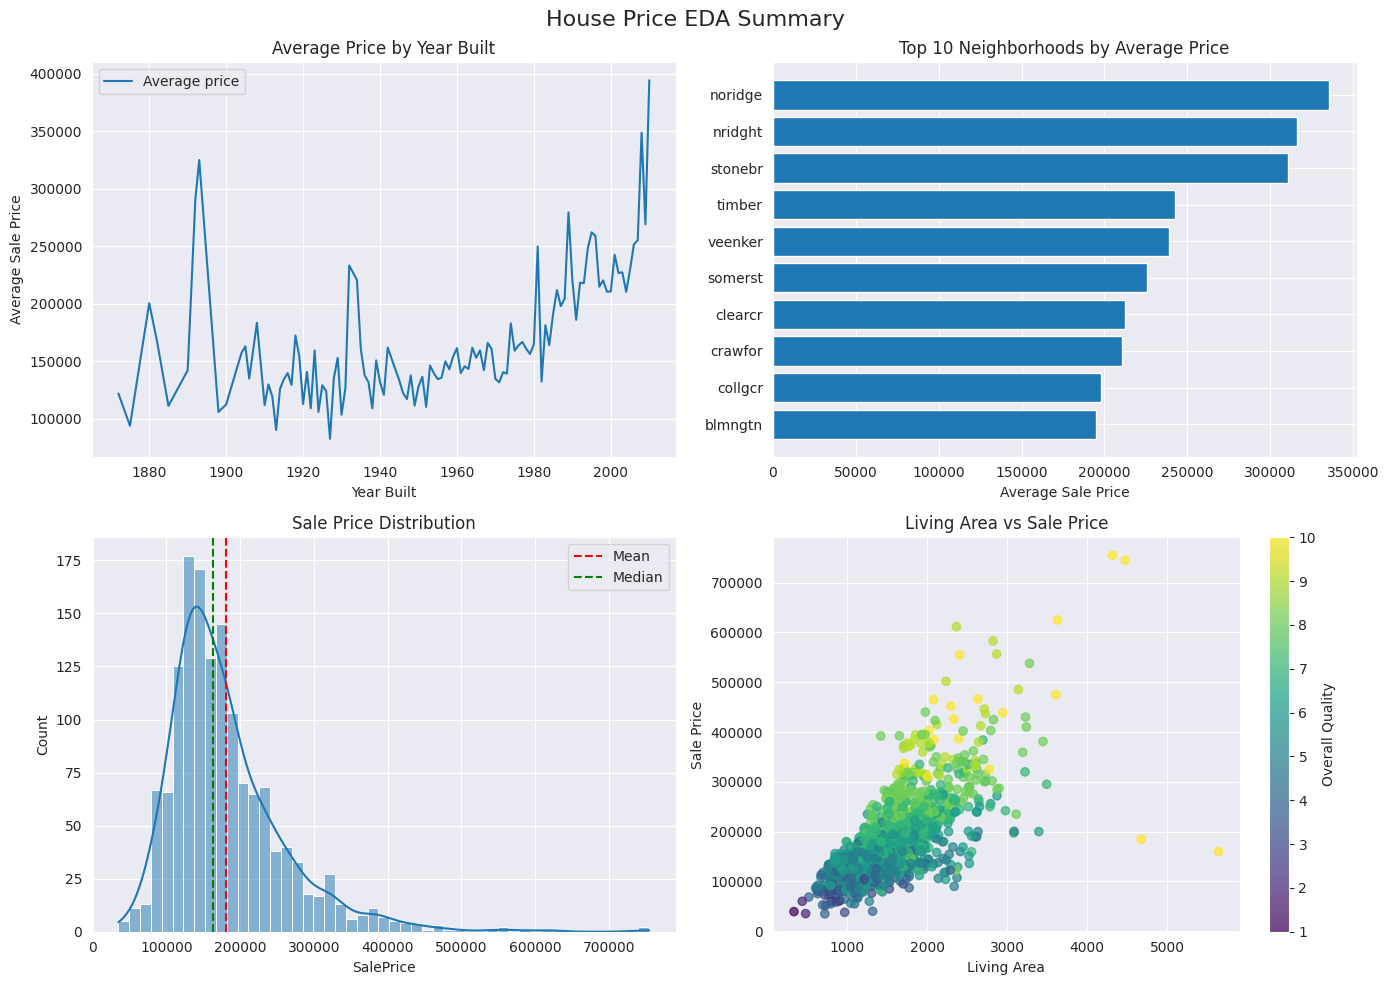

Dashboard saved successfully as eda_dashboard.png


In [ ]:

# Step 10.3: Final EDA Dashboard

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Average SalePrice by YearBuilt
year_price = df.groupby("YearBuilt")["SalePrice"].mean()

axes[0, 0].plot(
    year_price.index,
    year_price.values,
    label="Average price"
)

axes[0, 0].set_title("Average Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")
axes[0, 0].legend()


# Panel 2: Top 10 Neighborhoods by Mean SalePrice
neighborhood_price = (
    df.groupby("Neighborhood")["SalePrice"]
    .mean()
    .nlargest(10)
)

axes[0, 1].barh(
    neighborhood_price.index,
    neighborhood_price.values
)

axes[0, 1].set_title("Top 10 Neighborhoods by Average Price")
axes[0, 1].set_xlabel("Average Sale Price")
axes[0, 1].invert_yaxis()


# Panel 3: SalePrice Distribution with Mean and Median
sns.histplot(
    df["SalePrice"],
    kde=True,
    ax=axes[1, 0]
)

mean_price = df["SalePrice"].mean()
median_price = df["SalePrice"].median()

axes[1, 0].axvline(
    mean_price,
    color="red",
    linestyle="--",
    label="Mean"
)

axes[1, 0].axvline(
    median_price,
    color="green",
    linestyle="--",
    label="Median"
)

axes[1, 0].set_title("Sale Price Distribution")
axes[1, 0].legend()


# Panel 4: GrLivArea vs SalePrice coloured by OverallQual
scatter = axes[1, 1].scatter(
    df["GrLivArea"],
    df["SalePrice"],
    c=df["OverallQual"],
    cmap="viridis",
    alpha=0.7
)

axes[1, 1].set_title("Living Area vs Sale Price")
axes[1, 1].set_xlabel("Living Area")
axes[1, 1].set_ylabel("Sale Price")

fig.colorbar(scatter, ax=axes[1, 1], label="Overall Quality")


# Dashboard title and layout
fig.suptitle("House Price EDA Summary", fontsize=16)

plt.tight_layout()

# Save dashboard
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")

plt.show()

print("Dashboard saved successfully as eda_dashboard.png")



# Final EDA Project — Conclusion

## Key Findings

1. SalePrice shows a right-skewed distribution.
2. Log transformation helps reduce the skewness of SalePrice.
3. OverallQual and GrLivArea show strong relationships with SalePrice.
4. Higher-quality houses generally have higher selling prices.
5. Average house prices vary across neighborhoods.
6. Some unusually large houses have relatively low selling prices.
7. Several missing values represent the absence of house features rather than unknown information.

## Limitations

1. The analysis is based on a single housing dataset.
2. Correlation does not establish causation.
3. Outliers may represent genuine unusual sales.
4. Missing values require careful interpretation.

## Final Conclusion

Exploratory Data Analysis helped us understand the housing dataset through statistical summaries, visualizations, correlation analysis, outlier detection and data quality checks.

The analysis indicates that overall quality, living area and neighborhood are important factors associated with house selling prices.


In [ ]:

from google.colab import files

files.download("eda_dashboard.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>